In [107]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import contextily as cx

In [70]:
# constants

RAW_DATA_PATH = "../raw_data/"        # read files
PROC_DATA_PATH = "../processed_data/" # write files
CRS = 3310                            # "California Albers" projection mapping, since we're using CA data

PARCEL_COLS = ["APN", "UseCode", "Land", "Imps", "LatestDocu", "SitusCity"] # columns from parcels.geojson we plan to keep

# These have to do with parcel "use codes" (i.e. what sector is it based in).
# We refer to this: https://propinfo.acgov.org/UseCodeList/ in order to figure out what to drop.
# A use code is 4 digits.
DROP_SERIES   = {"4", "6"}            # DROP IF THIS IS FIRST DIGIT. industrial, institutional
DROP_PREFIXES = {"73", "74", "75"}    # "..." FIRST TWO DIGITS. ondos, co-ops, deed-restricted affordable
DROP_CODES    = {"1130", "1150", "1160", "1600", "3900", "9401", "9405", "9910"} # "..." ALL 4 DIGITS

# "DU" means "dwelling units"
# depending on the tier/category there is more DU.
DU_PER_ACRE = {
    "Tier 1 - 200ft": 160, "Tier 1 - Quarter Mile": 120, "Tier 1 - Half Mile": 100,
    "Tier 2 - 200ft": 140, "Tier 2 - Quarter Mile": 100, "Tier 2 - Half Mile": 80,
}

In [35]:
epc_data = gpd.read_file(DATA_PATH + "epc_data.geojson")
tod_data = gpd.read_file(DATA_PATH + "tod_zones.geojson")

tod_mask = tod_data.to_crs(3857).union_all() # we want parcels in tod zones, 
                                             # so we would like to match projections (3857: spherical mercator)

parcels_data = gpd.read_file(RAW_DATA_PATH + "parcels.geojson", # takes a while to load... (> 1 GB!!)
                             engine="pyogrio", use_arrow=True,
                             columns=PARCEL_COLS, mask=tod_mask)

parcels_data = (parcels_data
                .set_crs(3857, allow_override=True)      # data is assumed be in CRS 4326, but actually 3857. so label accordingly first
                .to_crs(CRS))                            # then reproject to 3310


In [36]:
parcels_data.to_parquet(PROC_DATA_PATH + "parcels_tod.parquet") # .parquet is faster to load

In [37]:
print("EPC dims:", epc_data.shape)
print("Parcel dims:", parcels_data.shape)
print("TOD zone dims:", tod_data.shape)

EPC dims: (353, 37)
Parcel dims: (71742, 7)
TOD zone dims: (665, 4)


In [38]:
epc_data.columns

Index(['OBJECTID', 'tract_geoid', 'county_fip', 'tot_pop_poc', 'tot_pop_se',
       'tot_pop_po', 'tot_pop_ci', 'tot_pop_ov', 'tot_hh', 'tot_fam',
       'pop_poc', 'pop_over75', 'pop_spfam', 'pop_lep', 'pop_below2',
       'pop_disabi', 'pop_hus_re', 'pop_zvhhs', 'pct_poc', 'pct_over75',
       'pct_spfam', 'pct_lep', 'pct_below2', 'pct_disab', 'pct_hus_re',
       'pct_zvhhs', 'poc_1_2', 'over75_1_2', 'spfam_1_2', 'lep_1_2',
       'disab_1_2', 'below2_1_2', 'hus_re_1_2', 'zvhh_1_2', 'epc_2050p',
       'epc_class', 'geometry'],
      dtype='object')

In [39]:
parcels_data.columns

Index(['APN', 'SitusCity', 'Land', 'Imps', 'LatestDocu', 'UseCode',
       'geometry'],
      dtype='object')

In [40]:
tod_data.columns

Index(['OBJECTID', 'zone_id', 'zone_label', 'geometry'], dtype='object')

In [41]:
epc_data = epc_data.to_crs(CRS)
tod_data = tod_data.to_crs(CRS)

In [53]:
parcels_data['geometry'].isna().any()                                                     # are there null geometries?
parcels_data = parcels_data.drop_duplicates(subset=['geometry'])                          # avoid double-counting of parcels
parcels_data = parcels_data[~((parcels_data['Land'] == 0) & (parcels_data['Imps'] == 0))] # remove exempt/public land
parcels_data.shape

(50157, 7)

In [59]:
code = parcels_data["UseCode"]
drop = (
    code.isna()
    | code.str[0].isin(DROP_SERIES)
    | code.str[:2].isin(DROP_PREFIXES)
    | code.isin(DROP_CODES)
)

parcels_data = parcels_data[~drop]
print(parcels_data.shape)

(47512, 7)


In [63]:
epc_data = epc_data[(epc_data['county_fip'] == 1) | (epc_data['county_fip'] == 85)] # keep only Alameda (1), Santa Clara (85)
epc_data.shape

(170, 37)

In [69]:
tod_data.zone_label.unique()

array(['Tier 1 - 200ft', 'Tier 1 - Half Mile', 'Tier 1 - Quarter Mile',
       'Tier 2 - 200ft', 'Tier 2 - Half Mile', 'Tier 2 - Quarter Mile'],
      dtype=object)

In [89]:
tod_data["du_per_acre"] = tod_data["zone_label"].map(DU_PER_ACRE)
parcels_data["acres"] = parcels_data.area / 4046.86

pts = parcels_data.copy()
pts.geometry = parcels_data.representative_point()
pts = gpd.sjoin(pts, tod_data[["zone_id", "zone_label", "du_per_acre", "geometry"]],
                predicate="within") # SPATIAL JOIN WITH TOD ZONES

# keep each parcel's most permissive zone
pts = pts.sort_values("du_per_acre", ascending=False)
pts = pts[~pts.index.duplicated()]

pts["max_units"] = np.floor(pts["acres"] * pts["du_per_acre"]).astype(int)

# This is where we track parcels in TOD zones (used pts as a temp variable)
parcels_tod = parcels_data.join(pts[["zone_id", "zone_label", "du_per_acre", "max_units"]],
                                how="inner")

In [90]:
parcels_tod = parcels_tod[parcels_tod["max_units"] >= 5].copy() # SB 79 projects need at least 5 units

In [91]:
reps = parcels_tod.copy()
reps.geometry = parcels_tod.representative_point()

# SPATIAL JOIN WITH EPC DATA
reps = gpd.sjoin(reps, epc_data[["epc_class", "geometry"]], how="left", predicate="within")
reps = reps[~reps.index.duplicated()]

parcels_tod["epc_class"] = reps["epc_class"]
parcels_tod["is_epc"] = parcels_tod["epc_class"].notna()

In [92]:
parcels_tod.shape

(43130, 14)

In [93]:
parcels_tod.head()

,APN,SitusCity,Land,Imps,LatestDocu,UseCode,geometry,acres,zone_id,zone_label,du_per_acre,max_units,epc_class,is_epc
4,1-121-12,OAKLAND,348168,812392,2018,8100,"POLYGON ((-200475.892 -21660.385, -200468.822 ...",0.086101,dfbc6562-3685-40f1-bceb-ef878f866567,Tier 1 - Half Mile,100,8,NaN,False
10,1-121-27-2,OAKLAND,187878,0,2020,3000,"POLYGON ((-200506.276 -21627.143, -200549.616 ...",0.234954,dfbc6562-3685-40f1-bceb-ef878f866567,Tier 1 - Half Mile,100,23,NaN,False
12,1-121-29-1,OAKLAND,1225840,1227328,2015,9400,"POLYGON ((-200512.371 -21664.423, -200563.904 ...",0.414844,dfbc6562-3685-40f1-bceb-ef878f866567,Tier 1 - Half Mile,100,41,NaN,False
14,1-123-1,OAKLAND,308579,90146,1993,8100,"POLYGON ((-200406.703 -21679.581, -200447.131 ...",0.338016,dfbc6562-3685-40f1-bceb-ef878f866567,Tier 1 - Half Mile,100,33,NaN,False
17,1-123-8,OAKLAND,282171,1370125,2000,9400,"POLYGON ((-200412.897 -21789.99, -200405.827 -...",0.086100,dfbc6562-3685-40f1-bceb-ef878f866567,Tier 1 - Half Mile,100,8,NaN,False


In [115]:
print("total allowed units:", parcels_tod["max_units"].sum())
print("share in an epc:", parcels_tod["is_epc"].mean().round(3)) # this number is ~50%! 
print(parcels_tod["zone_label"].value_counts())

total allowed units: 688068
share in an epc: 0.503
zone_label
Tier 1 - Half Mile       18369
Tier 2 - Half Mile       10308
Tier 2 - Quarter Mile     8449
Tier 1 - Quarter Mile     5559
Tier 2 - 200ft             366
Tier 1 - 200ft              79
Name: count, dtype: int64


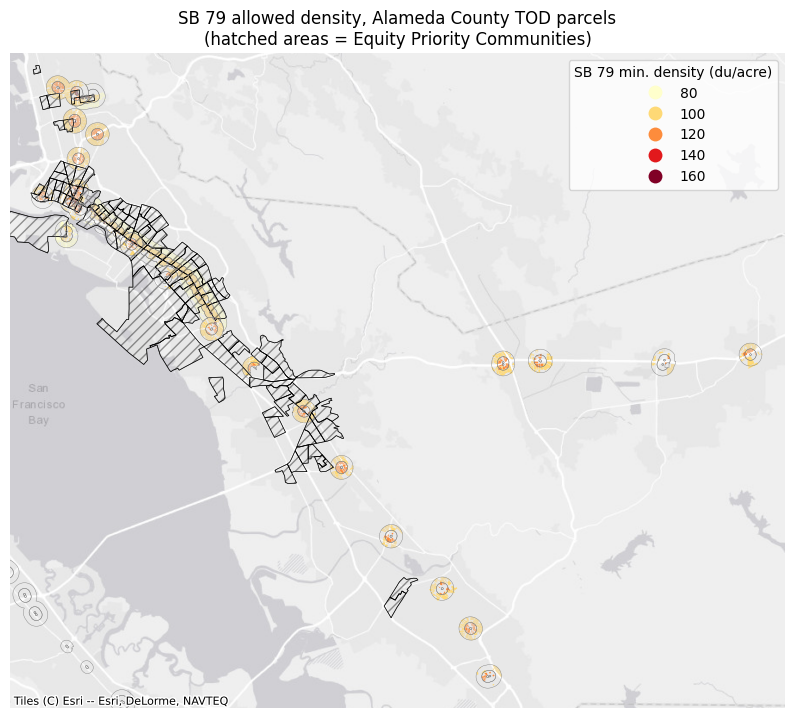

In [114]:
parcels_map = parcels_tod.to_crs(3857)
epc_map = epc_data.to_crs(3857)

fig, ax = plt.subplots(figsize=(10, 10))
parcels_map.plot(ax=ax, column="du_per_acre", categorical=True, cmap="YlOrRd",
                 linewidth=0, legend=True,
                 legend_kwds={"title": "SB 79 min. density (du/acre)", "loc": "upper right"})
epc_map.boundary.plot(ax=ax, color="black", linewidth=0.5)

xmin, ymin, xmax, ymax = parcels_map.total_bounds
ax.set_xlim(xmin - 2000, xmax + 2000)
ax.set_ylim(ymin - 2000, ymax + 2000)

epc_map.plot(ax=ax, color="none", edgecolor="black", linewidth=0.5, hatch="///", alpha=0.4)  # hatched = epc
tod_data.to_crs(3857).boundary.plot(ax=ax, color="gray", linewidth=0.3)                        # zone rings
cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas) 
ax.set_axis_off()
ax.set_title("SB 79 allowed density, Alameda County TOD parcels\n(hatched areas = Equity Priority Communities)")
plt.show()